In [ ]:
import json
import joblib
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

from jpeg_compression_detection.paths import (
    DATA_DIR,
    MODELS_DIR,
    FIGURES_DIR,
    display_path,
)

MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load the feature table.
data_path = DATA_DIR / 'results_240k_one_compression_filtered.csv'
df = pd.read_csv(data_path)

print(f"Number of rows before removal: {len(df)}")
print(f"Missing values:\n{df.isnull().sum()}")

# Remove rows with incomplete data.
df = df.dropna()

print(f"\nNumber of rows after removal: {len(df)}")

# Extract quality from the filename (for example, "..._q10" -> 10).
df['quality'] = df['filename'].str.extract(r'_q(\d+)')[0].astype(int)

print(f"\nQuality range: {df['quality'].min()} - {df['quality'].max()}")
print(f"Quality distribution:\n{df['quality'].value_counts().sort_index()}")

# Remove columns that are not used as predictors.
X = df.drop(['filename', 'extension', 'estimated_quality', 'quality'], axis=1)
y = df['quality']

# Split the data into training, validation, and test sets (60%, 20%, 20%).
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

print(f"\nTraining set: {len(X_train)} samples")
print(f"Validation set: {len(X_val)} samples")
print(f"Test set: {len(X_test)} samples")

# Define the candidate models.
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42),
    'SVR': SVR(kernel='rbf'),
}

# Train and evaluate the models.
results = {}

for model_name, model in models.items():
    print(f"\n{'='*50}")
    print(f"Training model: {model_name}")
    print('='*50)

    model.fit(X_train, y_train)
    checkpoint_slug = model_name.replace(' ', '_').lower()
    checkpoint_model_path = MODELS_DIR / f'{checkpoint_slug}_compression_model.pkl'
    joblib.dump(model, checkpoint_model_path)
    print(f"Checkpoint saved: {display_path(checkpoint_model_path)}")

    y_pred_train = model.predict(X_train)
    y_pred_val = model.predict(X_val)
    y_pred_test = model.predict(X_test)

    results[model_name] = {
        'train_mse': mean_squared_error(y_train, y_pred_train),
        'train_mae': mean_absolute_error(y_train, y_pred_train),
        'train_r2': r2_score(y_train, y_pred_train),
        'val_mse': mean_squared_error(y_val, y_pred_val),
        'val_mae': mean_absolute_error(y_val, y_pred_val),
        'val_r2': r2_score(y_val, y_pred_val),
        'test_mse': mean_squared_error(y_test, y_pred_test),
        'test_mae': mean_absolute_error(y_test, y_pred_test),
        'test_r2': r2_score(y_test, y_pred_test),
        'model': model,
    }
    checkpoint_metrics = {
        metric: float(value)
        for metric, value in results[model_name].items()
        if metric != 'model'
    }
    checkpoint_metrics_path = MODELS_DIR / f'{checkpoint_slug}_metrics.json'
    checkpoint_metrics_path.write_text(
        json.dumps(checkpoint_metrics, indent=2) + '\n',
        encoding='utf-8',
    )
    print(f"Metrics saved: {display_path(checkpoint_metrics_path)}")

    print(f"Train - MSE: {results[model_name]['train_mse']:.4f}, MAE: {results[model_name]['train_mae']:.4f}, R²: {results[model_name]['train_r2']:.4f}")
    print(f"Val   - MSE: {results[model_name]['val_mse']:.4f}, MAE: {results[model_name]['val_mae']:.4f}, R²: {results[model_name]['val_r2']:.4f}")
    print(f"Test  - MSE: {results[model_name]['test_mse']:.4f}, MAE: {results[model_name]['test_mae']:.4f}, R²: {results[model_name]['test_r2']:.4f}")

# Select the best model using validation R² only.
best_model_name = max(results, key=lambda candidate: results[candidate]['val_r2'])
print(f"\nBest model by validation R²: {best_model_name}")
print(f"Validation R²: {results[best_model_name]['val_r2']:.4f}")

print(f"\n{'='*50}")
print("RESULTS SUMMARY (test set)")
print('='*50)

results_df = pd.DataFrame({
    model_name: {
        'MSE': result['test_mse'],
        'MAE': result['test_mae'],
        'R²': result['test_r2'],
    }
    for model_name, result in results.items()
}).T

print(results_df.sort_values('R²', ascending=False))


# Saving the model

In [ ]:
import json
import joblib

MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Save every trained model under a stable filename.
for model_name, result in results.items():
    model_path = MODELS_DIR / (
        model_name.replace(' ', '_').lower() + '_compression_model.pkl'
    )
    joblib.dump(result['model'], model_path)
    print(f"Saved model: {model_name} -> {display_path(model_path)}")

# Save the validation-selected model under a stable alias for downstream use.
best_model_path = MODELS_DIR / 'best_compression_model.pkl'
joblib.dump(results[best_model_name]['model'], best_model_path)
print(f"\nBest model ({best_model_name}) was also saved as: {display_path(best_model_path)}")

# Record the validation-only selection decision and the exact feature order.
selection_metadata = {
    'selected_model': best_model_name,
    'selection_metric': 'validation_r2',
    'feature_columns': list(X.columns),
    'models': {
        name: {
            metric: float(result[metric])
            for metric in (
                'train_mse', 'train_mae', 'train_r2',
                'val_mse', 'val_mae', 'val_r2',
                'test_mse', 'test_mae', 'test_r2',
            )
        }
        for name, result in results.items()
    },
}
selection_path = MODELS_DIR / 'quality_model_selection.json'
selection_path.write_text(
    json.dumps(selection_metadata, indent=2) + '\n',
    encoding='utf-8',
)
print(f"Selection metadata saved as: {display_path(selection_path)}")


# Loading and evaluating saved models

In [ ]:
import joblib
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Reuse the original train/validation/test partitions from the training cell.
# Reloading and resplitting the full table here would mix training rows into
# the apparent validation and test sets, producing data-leakage metrics.
print(f"Training set: {len(X_train)} samples")
print(f"Validation set: {len(X_val)} samples")
print(f"Test set: {len(X_test)} samples")

model_files = [
    path
    for path in MODELS_DIR.glob('*_compression_model.pkl')
    if path.name != 'best_compression_model.pkl'
]

loaded_results = {}
if not model_files:
    print(f"No saved models found in {display_path(MODELS_DIR)}")
else:
    print(f"Found {len(model_files)} models\n")

    for model_path in model_files:
        model_name = model_path.name.replace('_compression_model.pkl', '').replace('_', ' ').title()
        if model_name.lower() == 'svr':
            model_name = 'SVR'

        print(f"Loading model: {model_name}")
        loaded_model = joblib.load(model_path)

        y_pred_train = loaded_model.predict(X_train)
        y_pred_val = loaded_model.predict(X_val)
        y_pred_test = loaded_model.predict(X_test)

        loaded_results[model_name] = {
            'train_mse': mean_squared_error(y_train, y_pred_train),
            'train_mae': mean_absolute_error(y_train, y_pred_train),
            'train_r2': r2_score(y_train, y_pred_train),
            'val_mse': mean_squared_error(y_val, y_pred_val),
            'val_mae': mean_absolute_error(y_val, y_pred_val),
            'val_r2': r2_score(y_val, y_pred_val),
            'test_mse': mean_squared_error(y_test, y_pred_test),
            'test_mae': mean_absolute_error(y_test, y_pred_test),
            'test_r2': r2_score(y_test, y_pred_test),
            'model': loaded_model,
        }

        print(f"Train - MSE: {loaded_results[model_name]['train_mse']:.4f}, MAE: {loaded_results[model_name]['train_mae']:.4f}, R²: {loaded_results[model_name]['train_r2']:.4f}")
        print(f"Val   - MSE: {loaded_results[model_name]['val_mse']:.4f}, MAE: {loaded_results[model_name]['val_mae']:.4f}, R²: {loaded_results[model_name]['val_r2']:.4f}")
        print(f"Test  - MSE: {loaded_results[model_name]['test_mse']:.4f}, MAE: {loaded_results[model_name]['test_mae']:.4f}, R²: {loaded_results[model_name]['test_r2']:.4f}")
        print()

    print(f"{'='*50}")
    print("LOADED MODELS RESULTS SUMMARY (test set)")
    print('='*50)

    loaded_results_df = pd.DataFrame({
        model_name: {
            'MSE': result['test_mse'],
            'MAE': result['test_mae'],
            'R²': result['test_r2'],
        }
        for model_name, result in loaded_results.items()
    }).T
    print(loaded_results_df.sort_values('R²', ascending=False))


In [ ]:
import joblib

best_model_path = MODELS_DIR / 'best_compression_model.pkl'
loaded_model = joblib.load(best_model_path)

# The loaded best model is available for downstream single-model analyses.


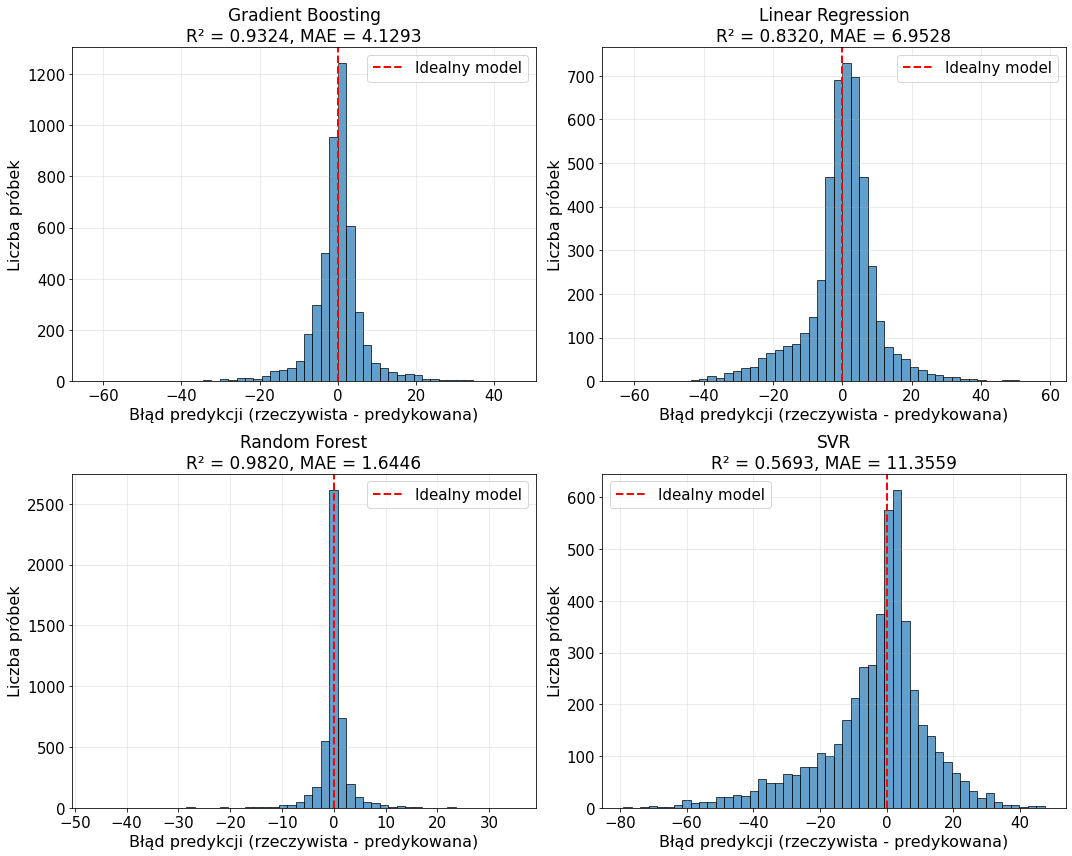

In [ ]:
# Font size control for plots
FONT_SIZE = 16

# Visualization of results with histograms
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.ravel()

for idx, (name, res) in enumerate(loaded_results.items()):
    y_pred_test = res['model'].predict(X_test)
    
    # Calculate prediction errors
    errors = y_test.values - y_pred_test
    
    # Error histogram
    axes[idx].hist(errors, bins=50, alpha=0.7, edgecolor='black')
    axes[idx].axvline(x=0, color='r', linestyle='--', lw=2, label='Ideal model')
    axes[idx].set_xlabel('Prediction error (actual - predicted)', fontsize=FONT_SIZE)
    axes[idx].set_ylabel('Number of samples', fontsize=FONT_SIZE)
    axes[idx].set_title(f'{name}\nR² = {res["test_r2"]:.4f}, MAE = {res["test_mae"]:.4f}', fontsize=FONT_SIZE + 1)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].legend(fontsize=FONT_SIZE - 1)
    axes[idx].tick_params(labelsize=FONT_SIZE - 1)

plt.tight_layout()
plt.show()


# Validation boxplots

In [ ]:
# Use the full validation set for this boxplot
sample_size = int(len(X_val) * 1)
sample_indices = np.random.choice(len(X_val), size=sample_size, replace=False)

X_val_sample = X_val.iloc[sample_indices]
y_val_sample = y_val.iloc[sample_indices]

# Visualize the models on the full validation set
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.ravel()

# Pre-compute unique qualities once - every 10
unique_qualities = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90])

for idx, (name, res) in enumerate(loaded_results.items()):
    # Get predictions for sample
    y_pred_val_model = res['model'].predict(X_val_sample)
    
    # Vectorized grouping - much faster than loop
    box_data = [y_pred_val_model[y_val_sample.values == quality] for quality in unique_qualities]
    
    # Create box plot with minimal features
    bp = axes[idx].boxplot(box_data, positions=unique_qualities, widths=2, 
                            patch_artist=True, showfliers=True,
                            medianprops=dict(color='red', linewidth=1.5),
                            flierprops=dict(marker='o', markerfacecolor='red', markersize=3, alpha=0.5))
    
    # Vectorized styling
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)
    
    # Plot ideal line
    axes[idx].plot(unique_qualities, unique_qualities, 'r--', lw=2, label='Ideal prediction')
    
    # Set labels and title
    axes[idx].set_xlabel('Actual quality', fontsize=FONT_SIZE)
    axes[idx].set_ylabel('Predicted quality', fontsize=FONT_SIZE)
    axes[idx].set_title(f'{name}\nR² = {res["val_r2"]:.4f}, MAE = {res["val_mae"]:.4f}', fontsize=FONT_SIZE + 1)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].legend(fontsize=FONT_SIZE - 1)
    axes[idx].tick_params(labelsize=FONT_SIZE - 1)
    axes[idx].set_xlim(5, 95)
    axes[idx].set_ylim(5, 95)

plt.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
figure_path = FIGURES_DIR / 'models_validation_comparison_boxplot_full_validation.png'
plt.savefig(figure_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"Plot saved as '{display_path(figure_path)}'")
print(f"Number of samples: {sample_size} (100% of {len(X_val)})")


In [ ]:
# Randomly select 10% of the validation data
# sample_size = int(len(X_val) * 0.1)
# sample_indices = np.random.choice(len(X_val), size=sample_size, replace=False)

# X_val_sample = X_val.iloc[sample_indices]
# y_val_sample = y_val.iloc[sample_indices]

# Visualize the models on the full validation set without outliers
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.ravel()

# Pre-compute unique qualities once - every 10
unique_qualities = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90])

for idx, (name, res) in enumerate(loaded_results.items()):
    # Get predictions for sample
    y_pred_val_model = res['model'].predict(X_val_sample)
    
    # Vectorized grouping - much faster than loop
    box_data = [y_pred_val_model[y_val_sample.values == quality] for quality in unique_qualities]
    
    # Create box plot with minimal features
    bp = axes[idx].boxplot(box_data, positions=unique_qualities, widths=2, 
                            patch_artist=True, showfliers=False,
                            medianprops=dict(color='red', linewidth=1.5))
    
    # Vectorized styling
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)
    
    # Plot ideal line
    axes[idx].plot(unique_qualities, unique_qualities, 'r--', lw=2, label='Ideal prediction')
    
    # Set labels and title
    axes[idx].set_xlabel('Actual quality', fontsize=FONT_SIZE)
    axes[idx].set_ylabel('Predicted quality', fontsize=FONT_SIZE)
    axes[idx].set_title(f'{name}\nR² = {res["val_r2"]:.4f}, MAE = {res["val_mae"]:.4f}', fontsize=FONT_SIZE + 1)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].legend(fontsize=FONT_SIZE - 1)
    axes[idx].tick_params(labelsize=FONT_SIZE - 1)

plt.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
figure_path = FIGURES_DIR / 'models_validation_comparison_boxplot_full_validation_no_outliers.png'
plt.savefig(figure_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"Plot saved as '{display_path(figure_path)}'")
print(f"Number of samples: {sample_size} (100% of {len(X_val)})")


# Test on JFIF (ThisPersonDoesNotExist)

# Moved to ML-compression-tests